In [89]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.differentiate import jacobian

In [90]:
##### calibration
p_cent = 720 # image is 1440 wide

k0 = 1200 # measurement (+- 1)

k_cali = np.array([800, 600, 400]) # measurements (+- 1)
lamda_cali = np.array([400, 600, 800]) # literature values of wavelength (manual)

In [91]:
# fit model for wavelength depending on dial position k
def lamda_c (kk, bb):
    return bb * (kk - k0)

b = -1.0 +- 0.0009284766908852593


<ErrorbarContainer object of 3 artists>

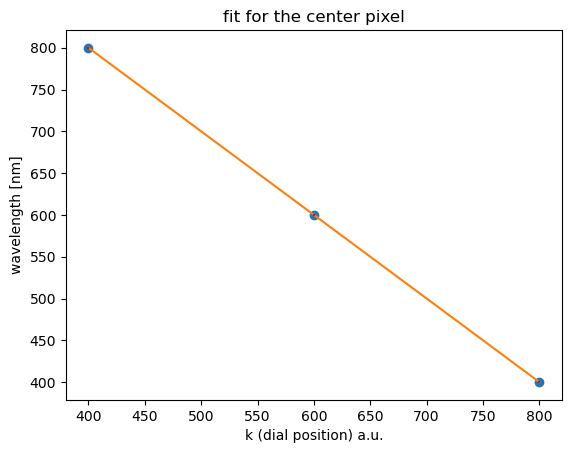

In [92]:
std_k = 1
std_k_cali = np.ones(len(k_cali)) * std_k # uncertenties of k values

# first fit to convert x-error to y-error
popt, pcov = curve_fit(lamda_c, k_cali, lamda_cali, absolute_sigma=True)
b_prov = popt[0]
std_lamda_cali = np.abs(b_prov * std_k_cali)

# actual fit
popt, pcov = curve_fit(lamda_c, k_cali, lamda_cali, sigma=std_lamda_cali, absolute_sigma=True)
b = popt[0]
std_b = np.sqrt(pcov[0, 0])
print('b =', b, '+-', std_b)

plt.plot(k_cali, lamda_cali, linestyle='', marker='o')
plt.plot(k_cali, lamda_c(k_cali, b))
plt.xlabel('k (dial position) a.u.')
plt.ylabel('wavelength [nm]')
plt.title('fit for the center pixel')
plt.errorbar(k_cali, lamda_cali, std_lamda_cali, linestyle = '', color='r')

In [93]:
p_pcali = np.array([1440, 1080, 720, 360, 0]) # measurment of pixel position from image (+- 1)
k_pcali = np.array([632.5, 622.5, 612.5, 602.5, 592.5]) # measurment of k (+- 1)
lamda_pcali = np.array([587.5, 587.5, 587.5, 587.5, 587.5]) # literaure values from manual (wavelength)

pk_pcali = np.stack((p_pcali, k_pcali))

In [94]:
# fit model including pixel position
def lamda_p (pk, dd):
    pp = pk[0]
    kk = pk[1]
    return b * ((kk - k0) - (pp - p_cent) / dd)

d = 35.99999999999998 +- 0.03162277660167581


Text(0.5, 1.0, 'estimated middle k-value for pixel position')

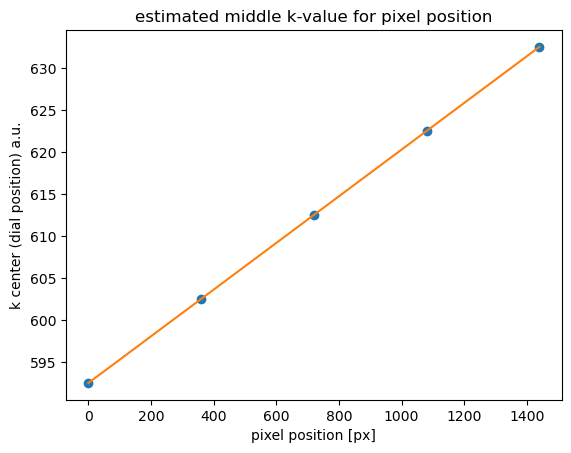

In [95]:
std_p = 1
std_p_pcali = np.ones(len(p_pcali)) * std_p # errors of the pixels

# first fit to determine y-error from x-error
popt, pcov = curve_fit(lamda_p, pk_pcali, lamda_pcali, absolute_sigma=True)
d_prov = popt[0]
std_lamda_pcali = np.abs(std_p_pcali / d_prov)

# actual fit
popt, pcov = curve_fit(lamda_p, pk_pcali, lamda_pcali, sigma=std_lamda_pcali, absolute_sigma=True)
d = popt[0]
std_d = np.sqrt(pcov[0, 0])
print('d =', d, '+-', std_d)

plt.plot(p_pcali, k_pcali, linestyle='', marker='o')
plt.plot(p_pcali, lamda_p(pk_pcali, d) / b + k0 + (p_pcali - p_cent) / d)
plt.ylabel('k center (dial position) a.u.') 
plt.xlabel('pixel position [px]')
plt.title('estimated middle k-value for pixel position')

In [98]:
saveparams = open("popt.txt", "w")
saveparams.write(str(k0))
saveparams.write("\n")
saveparams.write(str(b))
saveparams.write("\n")
saveparams.write(str(std_b))
saveparams.write("\n")
saveparams.write(str(d))
saveparams.write("\n")
saveparams.write(str(std_d))
saveparams.close()

# final fit function
def lamda (pp, kk):
    return b * ((kk - k0) - (pp - p_cent) / d)

In [99]:
print(lamda(0, 1000))
print(lamda(1440, 1000))

180.0
220.0


In [109]:
def f_lamda(z):
    fk0 = z[0]
    fb = z[1]
    fd = z[2]
    fp = z[3]
    fk = z[4]
    return fb * ((fk - fk0) - (fp - p_cent) / fd)

In [114]:
z = np.array([k0, b, d, 720, 0])
std_z = np.array([1, std_b, std_d, 1, 1])

jac = jacobian(f_lamda, z).df
print(np.sqrt(jac**2 @ std_z.transpose()**2))

1.8005973773394237


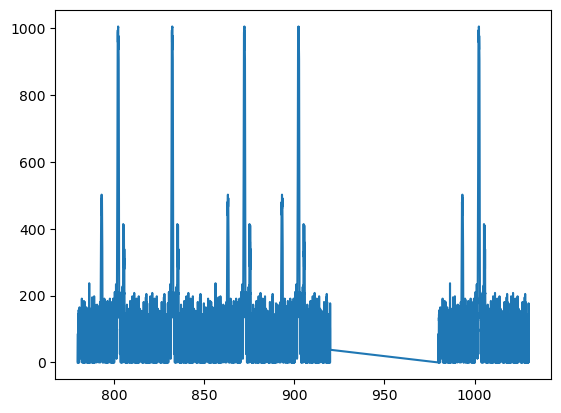

In [108]:
##### go to other jupyter to create the solar spectrum from images

data = np.loadtxt("images/spectrum.txt", delimiter=',')
wavelength = data[:, 0]
intensity = data[:, 1]
plt.plot(wavelength, intensity)